# Late Delivery and Customer Reviews
Does late delivery hurt review scores? Data: 95,560 delivered orders with a review, Jan 2017 - Aug 2018 (one review per order, latest kept).

## 1. Setup and data load

In [ ]:
import pandas as pd
from getpass import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=getpass("PostgreSQL password: "),
    host="localhost",
    port=5432,
    database="olist_ecommerce",
)
engine = create_engine(url)

### Quick test

In [ ]:
df = pd.read_sql("select count(*) as n from orders", engine)
df

### One row per order: latest review only, delivered orders, Jan 2017 - Aug 2018

In [ ]:
query = """
with ranked as (
    select
        order_id,
        review_score,
        row_number() over (partition by order_id order by review_answer_timestamp desc) as rn
    from order_reviews
), cte2 as (
    select order_id, review_score
    from ranked
    where rn = 1
)
select
    o.order_id,
    to_char(o.order_purchase_timestamp, 'YYYY-MM') as order_month,
    r.review_score,
    (o.order_delivered_customer_date::date - o.order_estimated_delivery_date::date) as days_late,
    case when o.order_delivered_customer_date::date > o.order_estimated_delivery_date::date
         then 1 else 0 end as is_late
from orders o
join cte2 r
    on r.order_id = o.order_id
where o.order_status = 'delivered'
  and o.order_delivered_customer_date is not null
  and to_char(o.order_purchase_timestamp, 'YYYY-MM') between '2017-01' and '2018-08'
"""

df_reviews = pd.read_sql(query, engine)

In [ ]:
print(df_reviews.shape)
print(df_reviews["is_late"].sum())
df_reviews.head()

## 2. Data checks and EDA

In [ ]:
df_reviews.info()

In [ ]:
df_reviews.describe()

### Review score distribution: 5 stars dominate, 1 star is the second biggest group

In [ ]:
df_reviews["review_score"].value_counts().sort_index()

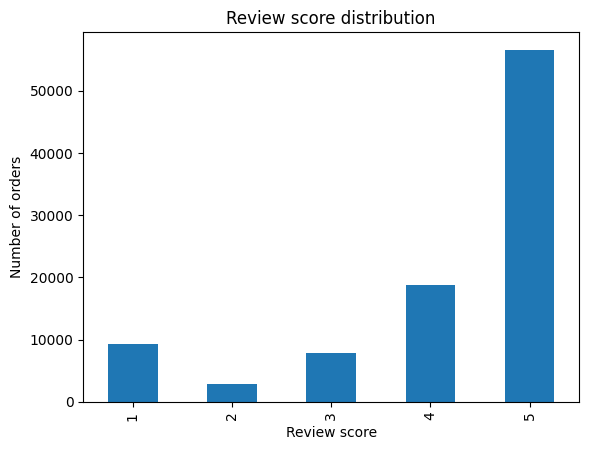

In [23]:
import matplotlib.pyplot as plt
counts = df_reviews["review_score"].value_counts().sort_index()
counts.plot(kind="bar")
plt.xlabel("Review score")
plt.ylabel("Number of orders")
plt.title("Review score distribution")
plt.show()

### Range=(-40, 40) is only for plotting; outliers are kept in the data. Bins are 1 day wide

In [ ]:
df_reviews["days_late"].plot(kind="hist", bins=80, range=(-40,40))
plt.axvline(0, color="red")
plt.xlabel("Days Late (negative means early)")
plt.title("Delivery vs estimated date")
plt.show()

### Same delay buckets as SQL Q3

In [ ]:
df_reviews["bucket"] = pd.cut(df_reviews["days_late"], bins = [-float('inf'), 0, 3, 7, float('inf')], labels = ["on_time", "1-3_days_late", "4-7_days_late", "8+_days_late"])
df_reviews.groupby("bucket", observed=True)["review_score"].mean()

### Correlation is weak to moderate because scores stay flat for early orders and drop only after an order is late

In [ ]:
a = df_reviews["days_late"].corr(df_reviews["review_score"])
b = df_reviews["days_late"].corr(df_reviews["review_score"], method = "spearman")
print(f"Pearson correlation: {a:.3f}")
print(f"Spearman correlation: {b:.3f}")

## 3. Hypothesis tests

### H0: late and on-time orders have the same review scores. 
### H1: they differ. alpha = 0.05

### Split review score into two groups 

In [ ]:
late_scores = df_reviews.loc[df_reviews["is_late"]==1, "review_score"]
ontime_scores = df_reviews.loc[df_reviews["is_late"]==0, "review_score"]

In [ ]:
print(len(late_scores), len(ontime_scores))
print(late_scores.mean(), ontime_scores.mean())

### Mann-Whitney U: scores are ordinal (1-5) and skewed, so a rank-based test fits

In [ ]:
from scipy.stats import mannwhitneyu

stat, p = mannwhitneyu(late_scores, ontime_scores, alternative="two-sided")
print(stat, p)

### Welch's t-test: compares averages without assuming equal variance; CI is for (late - on-time)

In [ ]:
from scipy.stats import ttest_ind

res = ttest_ind(late_scores, ontime_scores, equal_var=False)
print(res.statistic, res.pvalue)
print(res.confidence_interval(confidence_level=0.95))

### Chi-square: is being late related to getting a 1-2 star review?

In [ ]:
df_reviews["low_review"] = (df_reviews["review_score"] <= 2).astype(int)
table = pd.crosstab(df_reviews["is_late"], df_reviews["low_review"])
print(table)

In [ ]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(table)
print(chi2, p, dof)
print(expected.round(1))

### Average review score falls as the delay grows

In [ ]:
bucket_avg = df_reviews.groupby("bucket", observed=True)["review_score"].mean()
bucket_avg.plot(kind="bar")
plt.ylabel("Average review score")
plt.xlabel("Delivery delay")
plt.title("Review score falls as delay grows")
plt.xticks(rotation=0)
plt.show()

## 4. Conclusions
- Late orders (6.67%) average 2.27 stars vs 4.29 for on-time orders.
- Scores fall as delay grows: 4.29 (on time), 3.29 (1-3 days), 2.10 (4-7 days), 1.70 (8+ days).
- 62.4% of late orders get a 1-2 star review vs 9.3% of on-time orders, about 6.7 times as likely.
- Mann-Whitney U (p < 0.001), Welch's t-test (gap -2.02 stars, 95% CI -2.06 to -1.98) and chi-square (p < 0.001) all agree.
- Correlation is weak to moderate (Pearson -0.27, Spearman -0.18) because the effect is a step at zero, not a steady slope.
- This is an association, not proof of cause: late orders may differ in other ways (distance, seller, product).